In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from src.session_loader import Session

2024-12-03 15:39:38.483230: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-12-03 15:39:38.483287: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-12-03 15:39:38.483294: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
reg_matrix = np.load(r'processed-data/registration/Oct_2024_synthetic/1001_registered_ids.npy')
indexing = np.load(r'processed-data/registration/Oct_2024_synthetic/1001_session_indexing.npy', allow_pickle=True).item()
print(reg_matrix.shape, indexing)

(250, 6) {'HBTD1': 0, 'HBTD2': 1, 'HBTD3': 2, 'HBTD4': 3, 'HBTD5': 4, 'HBTD6': 5}


In [3]:
session_file = pd.read_csv('data/SESSION_FILE_insilico_2024-11-26_14-25-32.csv')
session_file.head()

,Excluded,Session,Cohort,Date,Mouse,Pair,Miniscope video,Criteria,Sex,Final Outcome,...,Maximum Shift,True Number,ManualAnnotationSide,Normalized components,Num of Liberation cells,% of Liberation cells,Liberation Associated Cells Metadata Path,Num of Random cells,% of Random cells,Random Associated Cells Metadata Path
0,False,HBTD1,Oct_2024_synthetic,05.11.2024,1001,1001-0000,05.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
1,False,HBTD2,Oct_2024_synthetic,06.11.2024,1001,1001-0000,06.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.38,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
2,False,HBTD3,Oct_2024_synthetic,07.11.2024,1001,1001-0000,07.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.00,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
3,False,HBTD4,Oct_2024_synthetic,08.11.2024,1001,1001-0000,08.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.14,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
4,False,HBTD5,Oct_2024_synthetic,09.11.2024,1001,1001-0000,09.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...


In [4]:
session_file = session_file[session_file['Mouse'] == 1001]
session_file.head()

,Excluded,Session,Cohort,Date,Mouse,Pair,Miniscope video,Criteria,Sex,Final Outcome,...,Maximum Shift,True Number,ManualAnnotationSide,Normalized components,Num of Liberation cells,% of Liberation cells,Liberation Associated Cells Metadata Path,Num of Random cells,% of Random cells,Random Associated Cells Metadata Path
0,False,HBTD1,Oct_2024_synthetic,05.11.2024,1001,1001-0000,05.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
1,False,HBTD2,Oct_2024_synthetic,06.11.2024,1001,1001-0000,06.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.38,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
2,False,HBTD3,Oct_2024_synthetic,07.11.2024,1001,1001-0000,07.11.2024_1001,Silicon,M,NH,...,0,102,NaN,16.00,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
3,False,HBTD4,Oct_2024_synthetic,08.11.2024,1001,1001-0000,08.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.14,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
4,False,HBTD5,Oct_2024_synthetic,09.11.2024,1001,1001-0000,09.11.2024_1001,Silicon,M,NH,...,0,102,NaN,17.52,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...


In [5]:
pos_dic = {}

for i, row in session_file.iterrows():
    session = Session(row)
    positions = session.extract_neuron_positions(session.get_neuron_labels())
    pos_dic[session.session] = positions

pos_dic

{'HBTD1': array([[ 59., 336.],
        [103., 283.],
        [123., 315.],
        [106., 331.],
        [100., 367.],
        [110., 401.],
        [123., 413.],
        [142., 238.],
        [138., 324.],
        [147., 362.],
        [145., 387.],
        [148., 543.],
        [169.,  99.],
        [182., 126.],
        [183., 240.],
        [180., 270.],
        [174., 260.],
        [168., 292.],
        [168., 343.],
        [176., 375.],
        [173., 401.],
        [158., 417.],
        [165., 450.],
        [156., 483.],
        [178., 483.],
        [168., 487.],
        [203., 105.],
        [196., 259.],
        [197., 247.],
        [206., 269.],
        [190., 287.],
        [192., 296.],
        [202., 277.],
        [199., 324.],
        [189., 315.],
        [204., 311.],
        [211., 315.],
        [208., 393.],
        [201., 367.],
        [195., 389.],
        [194., 398.],
        [193., 415.],
        [206., 432.],
        [188., 447.],
        [210., 468.],
 

In [6]:
reg_matrix.shape

(250, 6)

In [7]:
def compute_distances(assignments, positions):
    """
    Compute distances between neuron pairs based on registration status.

    Parameters:
    - assignments: 2D numpy array (neurons x sessions) with registration IDs or NaN.
    - positions: Dictionary with session IDs as keys and neuron position arrays as values.

    Returns:
    - registered_distances: List of distances for neuron pairs that are registered in at least one shared session.
    - non_registered_distances: List of distances for neuron pairs where no sessions overlap in registration.
    """
    registered_distances = []
    non_registered_distances = []

    # Combine positions across sessions into a single array
    session_positions = np.concatenate(list(positions.values()), axis=0)

    # Iterate over all pairs of neurons
    for i in range(assignments.shape[0]):
        for j in range(i + 1, assignments.shape[0]):
            # Compute the Euclidean distance
            dist = np.linalg.norm(session_positions[i] - session_positions[j])
            
            # Check if there is at least one shared session where both neurons are registered
            shared_sessions = ~np.isnan(assignments[i, :]) & ~np.isnan(assignments[j, :])
            if np.any(shared_sessions):  # At least one session where both are registered
                registered_distances.append(dist)
            else:  # No sessions where both are registered
                non_registered_distances.append(dist)

    return registered_distances, non_registered_distances

In [8]:
reg_matrix.shape

(250, 6)

In [9]:
from scipy.spatial.distance import pdist

registered_distances = []
non_registered_distances = []

# Iterate over all pairs of neurons
for i in range(reg_matrix.shape[0]):
    neuron_positions = []
    for k, j in indexing.items():
        if not np.isnan(reg_matrix[i, j]):
            neuron_id = int(reg_matrix[i, j])
            neuron_positions.append(pos_dic[k][neuron_id, :])
    neuron_positions = np.array(neuron_positions)
    dists = pdist(neuron_positions)
    registered_distances.extend(list(dists))
    

    

In [10]:
pos_dic

{'HBTD1': array([[ 59., 336.],
        [103., 283.],
        [123., 315.],
        [106., 331.],
        [100., 367.],
        [110., 401.],
        [123., 413.],
        [142., 238.],
        [138., 324.],
        [147., 362.],
        [145., 387.],
        [148., 543.],
        [169.,  99.],
        [182., 126.],
        [183., 240.],
        [180., 270.],
        [174., 260.],
        [168., 292.],
        [168., 343.],
        [176., 375.],
        [173., 401.],
        [158., 417.],
        [165., 450.],
        [156., 483.],
        [178., 483.],
        [168., 487.],
        [203., 105.],
        [196., 259.],
        [197., 247.],
        [206., 269.],
        [190., 287.],
        [192., 296.],
        [202., 277.],
        [199., 324.],
        [189., 315.],
        [204., 311.],
        [211., 315.],
        [208., 393.],
        [201., 367.],
        [195., 389.],
        [194., 398.],
        [193., 415.],
        [206., 432.],
        [188., 447.],
        [210., 468.],
 

In [11]:
non_registered_distances = []

for k, s in pos_dic.items():
    dists = pdist(s)
    non_registered_distances.extend(list(dists))


In [12]:
registered_distances

[6.708203932499369,
 6.324555320336759,
 6.324555320336759,
 7.810249675906654,
 7.211102550927978,
 4.123105625617661,
 13.416407864998739,
 14.866068747318506,
 7.280109889280518,
 7.280109889280518,
 6.324555320336759,
 10.63014581273465,
 5.385164807134504,
 6.082762530298219,
 11.704699910719626,
 15.620499351813308,
 7.810249675906654,
 6.324555320336759,
 6.324555320336759,
 6.082762530298219,
 6.082762530298219,
 6.324555320336759,
 5.830951894845301,
 5.385164807134504,
 10.0,
 8.94427190999916,
 6.082762530298219,
 13.45362404707371,
 18.867962264113206,
 7.615773105863909,
 3.605551275463989,
 16.97056274847714,
 10.816653826391969,
 24.20743687382041,
 13.45362404707371,
 7.211102550927978,
 5.656854249492381,
 8.246211251235321,
 6.324555320336759,
 5.385164807134504,
 8.06225774829855,
 6.324555320336759,
 6.324555320336759,
 4.0,
 8.48528137423857,
 2.8284271247461903,
 14.422205101855956,
 11.661903789690601,
 6.324555320336759,
 10.295630140987,
 6.324555320336759,
 14

In [13]:
non_registered_distances

[68.8839603971781,
 67.35725647619564,
 47.265209192385896,
 51.40038910358559,
 82.61961026293939,
 100.12492197250393,
 128.42507543311004,
 79.90619500389191,
 91.76055797563569,
 99.98499887483122,
 225.32199182503248,
 261.283371074395,
 243.37008854828483,
 156.81836627130127,
 137.82960494755835,
 137.84411485442533,
 117.5457357797381,
 109.22453936730518,
 123.3288287465668,
 131.2288078129189,
 127.91403363196706,
 155.66630977832037,
 176.11927776367924,
 189.12958520548815,
 186.23103930333417,
 272.2076413328619,
 157.15597347857954,
 164.21023110634732,
 161.54875425084526,
 139.86421987055874,
 138.88484438555562,
 154.69324484281788,
 140.51334456200237,
 131.68523075880606,
 147.13938969562162,
 153.44380078712857,
 159.53056133543816,
 145.34441853748632,
 145.96232390586277,
 148.5563866011825,
 155.5538491969903,
 175.57049866079439,
 170.182255244194,
 200.5617112013158,
 208.06249061279644,
 224.0089283934906,
 199.07787421006887,
 191.7185437040455,
 174.74839055

In [14]:
from src.plotting import plot_boxplots

def gather_distance_data(registered_distances, non_registered_distances, cohort, animal, distance_data):
    """Add average distances for an animal to the collective cohort data."""
    avg_registered = np.mean(registered_distances)
    avg_non_registered = np.mean(non_registered_distances)
    distance_data.append({
        'Animal': animal,
        'Cohort': cohort,
        'Category': 'Registered',
        'Distance': avg_registered
    })
    distance_data.append({
        'Animal': animal,
        'Cohort': cohort,
        'Category': 'Non-Registered',
        'Distance': avg_non_registered
    })



/home/aagafono/projects/helping-behaviour-calcium-imaging/src/plotting.py:842: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.swarmplot(
/home/aagafono/miniconda3/envs/mescore/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 22758.
  res = hypotest_fun_out(*samples, **kwds)


<Axes: xlabel='Group', ylabel='Distance'>

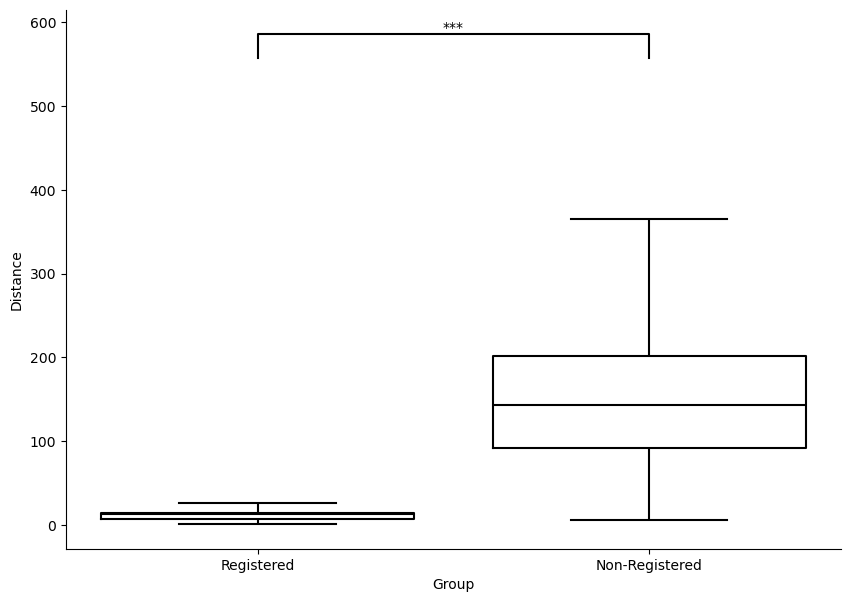

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))

plot_boxplots(registered_distances, non_registered_distances, ax=ax, labels=['Registered', 'Non-Registered'], ylabel='Distance')